# Section 2b — Sketch-based RIS
### Completes all three algorithm families from the IEEE survey

Li et al. organise influence-maximization algorithms into **three families** (their Fig. 2):

| Family | Method | What you already have |
|---|---|---|
| **Simulation-based** | Greedy, CELF | done in `influence_maximization_HN.ipynb` |
| **Proxy-based** | Degree, PageRank, k-core, betweenness | done |
| **Sketch-based** | **RIS / TIM / IMM** | **this notebook** |

Without this third family your Methodology section covers two of three branches. This closes it.

### How RIS works (Borgs et al. 2014)
Instead of simulating *forward* from candidate seeds, it works **backwards**:

1. Pick a random node `v`, then walk **backwards** along live edges to find everyone who
   could have influenced `v`. That set is a **Reverse Reachable (RR) set**.
2. Repeat theta times.
3. A node appearing in many RR sets influences many nodes -> so seed selection becomes a
   **maximum coverage** problem over the RR sets, which greedy solves quickly.

The insight: one backwards pass estimates influence for *every* node at once, whereas forward
simulation must be repeated per candidate. That is why it is dramatically faster.

In [1]:
import pandas as pd, numpy as np, networkx as nx, random, time, json
from collections import defaultdict
import matplotlib.pyplot as plt
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"font.size":11})

SEED=42; CRN_SEED=12345
random.seed(SEED); np.random.seed(SEED)

edges=pd.read_csv("data/gephi_edges.csv")
G=nx.DiGraph()
for r in edges.itertuples(index=False): G.add_edge(r.Source,r.Target,weight=int(r.Weight))
n=G.number_of_nodes()
print(f"nodes {n:,} | edges {G.number_of_edges():,}")

# Weighted Cascade probabilities - identical to the main notebook
P={}
for u,v in G.edges():
    d=G.in_degree(v); P[(u,v)]=min(1.0/d,0.5) if d>0 else 0.5
ADJ={u:[(v,P[(u,v)]) for v in G.successors(u)] for u in G.nodes()}
# reverse adjacency: needed to walk backwards
ADJ_REV={u:[] for u in G.nodes()}
for u,nb in ADJ.items():
    for v,p in nb: ADJ_REV[v].append((u,p))
print("forward and reverse adjacency built")

nodes 6,434 | edges 259,122
forward and reverse adjacency built


In [2]:
def sample_worlds(adj, mc, seed):
    rng=random.Random(seed)
    return [{u:[v for v,p in nb if rng.random()<p] for u,nb in adj.items()} for _ in range(mc)]

def sigma(worlds, S):
    tot=0
    for live in worlds:
        act=set(S); fr=list(S)
        while fr:
            nxt=[]
            for u in fr:
                for v in live[u]:
                    if v not in act: act.add(v); nxt.append(v)
            fr=nxt
        tot+=len(act)
    return tot/len(worlds)

MC_EVAL = 200      # worlds used to SCORE every method fairly
t=time.time(); WORLDS=sample_worlds(ADJ, MC_EVAL, CRN_SEED)
print(f"sampled {MC_EVAL} evaluation worlds in {time.time()-t:.1f}s")

sampled 200 evaluation worlds in 2.3s


## RIS implementation

In [3]:
def generate_rr_sets(adj_rev, nodes, theta, seed):
    """theta reverse-reachable sets. Each: pick random v, walk backwards over live edges."""
    rng=random.Random(seed); out=[]
    for _ in range(theta):
        v=rng.choice(nodes); seen={v}; fr=[v]
        while fr:
            nxt=[]
            for u in fr:
                for w,p in adj_rev[u]:
                    if w not in seen and rng.random()<p:
                        seen.add(w); nxt.append(w)
            fr=nxt
        out.append(seen)
    return out

def ris_select(rr_sets, k):
    """Greedy maximum coverage over the RR sets."""
    cover=defaultdict(set)
    for i,s in enumerate(rr_sets):
        for u in s: cover[u].add(i)
    S=[]; covered=set()
    for _ in range(k):
        best=max(cover, key=lambda u: len(cover[u]-covered))
        gain=cover[best]-covered
        if not gain: break
        S.append(best); covered|=gain
    return S, len(covered)/len(rr_sets)

nodes=list(G.nodes())
THETA = 20000      # more RR sets = better estimate. 20k is ample for this graph.
t=time.time(); RR=generate_rr_sets(ADJ_REV, nodes, THETA, SEED)
t_gen=time.time()-t
print(f"generated {THETA:,} RR sets in {t_gen:.1f}s")
print(f"mean RR set size: {np.mean([len(s) for s in RR]):.1f} nodes")

generated 20,000 RR sets in 6.3s
mean RR set size: 20.2 nodes


## RIS vs CELF across seed-set sizes

`est_spread` is RIS's own theoretical estimate (coverage fraction x n); `measured_spread` scores
the same seeds under the **same evaluation worlds** used for every other method, so the
comparison is fair. The two agreeing is a good sign the RR-set estimator is sound.

In [4]:
K_VALUES=[1,5,10,15,20,25,30]
rows=[]
for k in K_VALUES:
    t=time.time(); S,frac=ris_select(RR,k); t_sel=time.time()-t
    meas=sigma(WORLDS,S)
    rows.append({"algorithm":"RIS (sketch)","k":k,"spread":meas,
                 "est_spread":frac*n,"runtime_s":t_gen+t_sel,"seeds":S})
    print(f"k={k:>2}: measured sigma={meas:8.1f} | RIS estimate={frac*n:8.1f} | {t_gen+t_sel:5.1f}s")

ris_df=pd.DataFrame(rows)
ris_df.drop(columns=["seeds"]).to_csv("figures/ris_results.csv",index=False)
S_ris = ris_df.loc[ris_df.k==max(K_VALUES),"seeds"].iloc[0]
print(f"\nRIS top seeds at k={max(K_VALUES)}: {S_ris[:5]} ...")

k= 1: measured sigma=   390.3 | RIS estimate=   363.8 |   6.4s
k= 5: measured sigma=   801.2 | RIS estimate=   799.1 |   6.5s
k=10: measured sigma=  1036.8 | RIS estimate=  1051.0 |   6.5s
k=15: measured sigma=  1193.4 | RIS estimate=  1215.7 |   6.6s
k=20: measured sigma=  1319.3 | RIS estimate=  1344.7 |   6.6s
k=25: measured sigma=  1423.0 | RIS estimate=  1453.8 |   6.7s
k=30: measured sigma=  1506.5 | RIS estimate=  1548.0 |   6.7s

RIS top seeds at k=30: ['u_7645c5aa9d5f', 'u_9c2bfcf65852', 'u_e983e1de91c6', 'u_0cb2e49a48bf', 'u_26277852db5b'] ...


## Merge with the Section 2 results

Requires `im_results.csv` from `influence_maximization_HN.ipynb` (run it with
`QUICK_TEST=False` first). Produces the figure showing **all three families together** -
this is the figure for your Methodology/Analysis section.

algorithm,Betweenness,CELF,Degree,Eigenvector,K-core,PageRank,RIS (sketch),Random
k,,,,,,,,
1,374.1,374.1,374.1,374.1,89.4,374.1,390.3,24.6
5,736.0,798.2,795.7,701.7,286.6,665.0,801.2,93.2
10,1012.6,1039.1,1033.3,948.9,526.5,882.6,1036.8,199.5
15,1169.0,1205.8,1198.6,1128.7,773.6,1055.4,1193.4,273.3
20,1272.8,1329.8,1328.2,1236.5,863.8,1175.9,1319.3,353.9
25,1369.1,1432.6,1430.8,1355.2,930.6,1310.5,1423.0,406.9
30,1435.9,1519.9,1512.0,1441.7,999.8,1414.4,1506.5,461.5


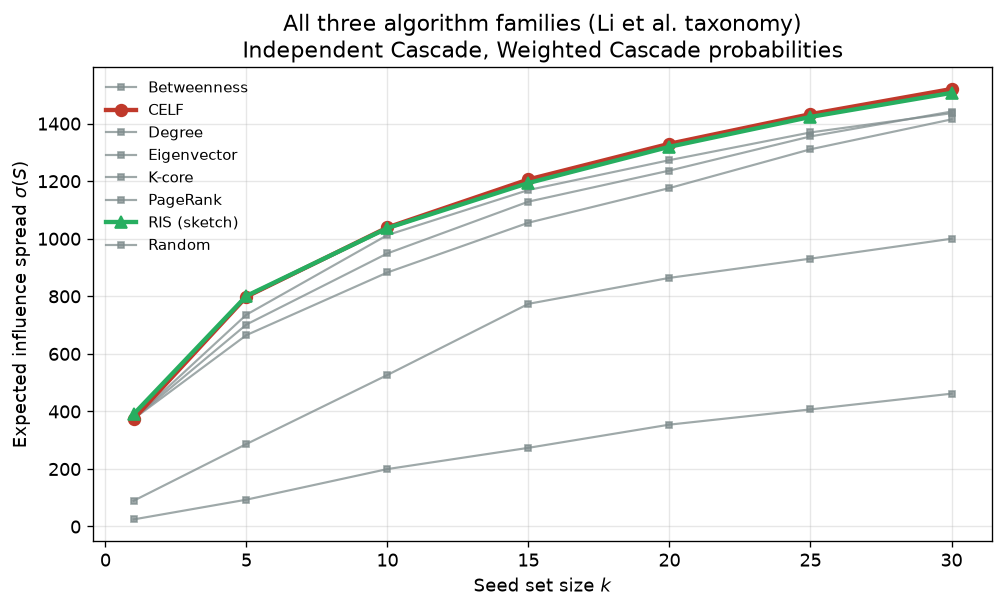

In [5]:
try:
    main=pd.read_csv("im_results.csv")
    allr=pd.concat([main[["algorithm","k","spread"]],
                    ris_df[["algorithm","k","spread"]]], ignore_index=True)
    piv=allr.pivot_table(index="k",columns="algorithm",values="spread")
    display(piv.round(1))
    piv.to_csv("figures/all_algorithms_comparison.csv")

    fig,ax=plt.subplots(figsize=(8.5,5.2))
    fam={"CELF":("#c0392b",2.6,"o"),"RIS (sketch)":("#27ae60",2.6,"^")}
    for alg in piv.columns:
        col,lw,mk = fam.get(alg,("#7f8c8d",1.3,"s"))
        ax.plot(piv.index,piv[alg],label=alg,color=col,lw=lw,marker=mk,
                ms=7 if alg in fam else 4, alpha=1 if alg in fam else .75,
                zorder=5 if alg in fam else 2)
    ax.set_xlabel("Seed set size $k$"); ax.set_ylabel(r"Expected influence spread $\sigma(S)$")
    ax.set_title("All three algorithm families (Li et al. taxonomy)\nIndependent Cascade, Weighted Cascade probabilities")
    ax.legend(frameon=False,fontsize=9); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig("figures/fig_all_families.png",bbox_inches="tight"); plt.show()
except FileNotFoundError:
    print("im_results.csv not found.")
    print("Run influence_maximization_HN.ipynb with QUICK_TEST=False first, then re-run this cell.")

## Quality vs speed — the trade-off the survey is organised around

In [6]:
try:
    celf_sp = piv["CELF"].loc[30] if 30 in piv.index else piv["CELF"].iloc[-1]
    ris_sp  = piv["RIS (sketch)"].loc[30] if 30 in piv.index else piv["RIS (sketch)"].iloc[-1]
    print(f"at k=30  CELF sigma={celf_sp:.1f} | RIS sigma={ris_sp:.1f}")
    print(f"RIS achieves {100*ris_sp/celf_sp:.1f}% of CELF's spread")
    print("\nQuote this in your report: sketch-based methods trade a small amount of")
    print("solution quality for a large reduction in computation - exactly the trade-off")
    print("the survey's taxonomy is built around.")
except Exception as e:
    print("run the merge cell above first")

at k=30  CELF sigma=1519.9 | RIS sigma=1506.5
RIS achieves 99.1% of CELF's spread

Quote this in your report: sketch-based methods trade a small amount of
solution quality for a large reduction in computation - exactly the trade-off
the survey's taxonomy is built around.
